# 02 - Exploratory Data Analysis

**Input:** `data/cleaned_products.csv`
**Goal:** Understand what drives gaming laptop prices and verify the patterns statistically.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/cleaned_products.csv")
print(df.shape)
print(df.columns.tolist())

Link               0
Name               0
Price              0
brand              0
model              0
cpu_model          0
ram_gb             0
gpu_model          0
vram_gb            0
storage_gb         0
refresh_rate_hz    0
screen_size        0
os                 0
group_id           0


count      1681.0
mean     165255.0
std       92350.0
min       43672.0
25%       99999.0
50%      135762.0
75%      207829.0
max      652299.0
Skewness (raw): 1.52
Skewness (log): 0.29


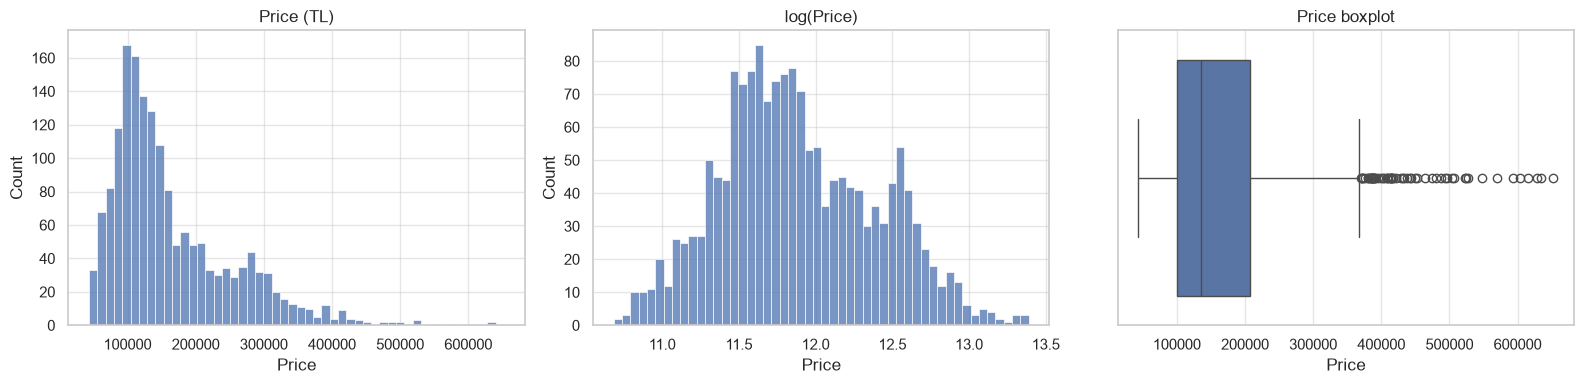

In [6]:
price = df["Price"]
print(price.describe().round(0).to_string())
print("Skewness (raw):", round(stats.skew(price), 2))
print("Skewness (log):", round(stats.skew(np.log(price)), 2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(price, bins=50, ax=axes[0]).set_title("Price (TL)")
sns.histplot(np.log(price), bins=50, ax=axes[1]).set_title("log(Price)")
sns.boxplot(x=price, ax=axes[2]).set_title("Price boxplot")
plt.tight_layout()
plt.show()

In [7]:
df["log_price"] = np.log(df["Price"])
num_cols = ["ram_gb", "vram_gb", "storage_gb", "refresh_rate_hz", "screen_size"]

# Spearman measures monotonic relationships and is robust to skew and outliers
spearman = df[num_cols + ["log_price"]].corr(method="spearman")["log_price"].drop("log_price")
print(spearman.round(2).sort_values(ascending=False).to_string())

vram_gb            0.62
ram_gb             0.60
refresh_rate_hz    0.48
screen_size        0.46
storage_gb         0.39


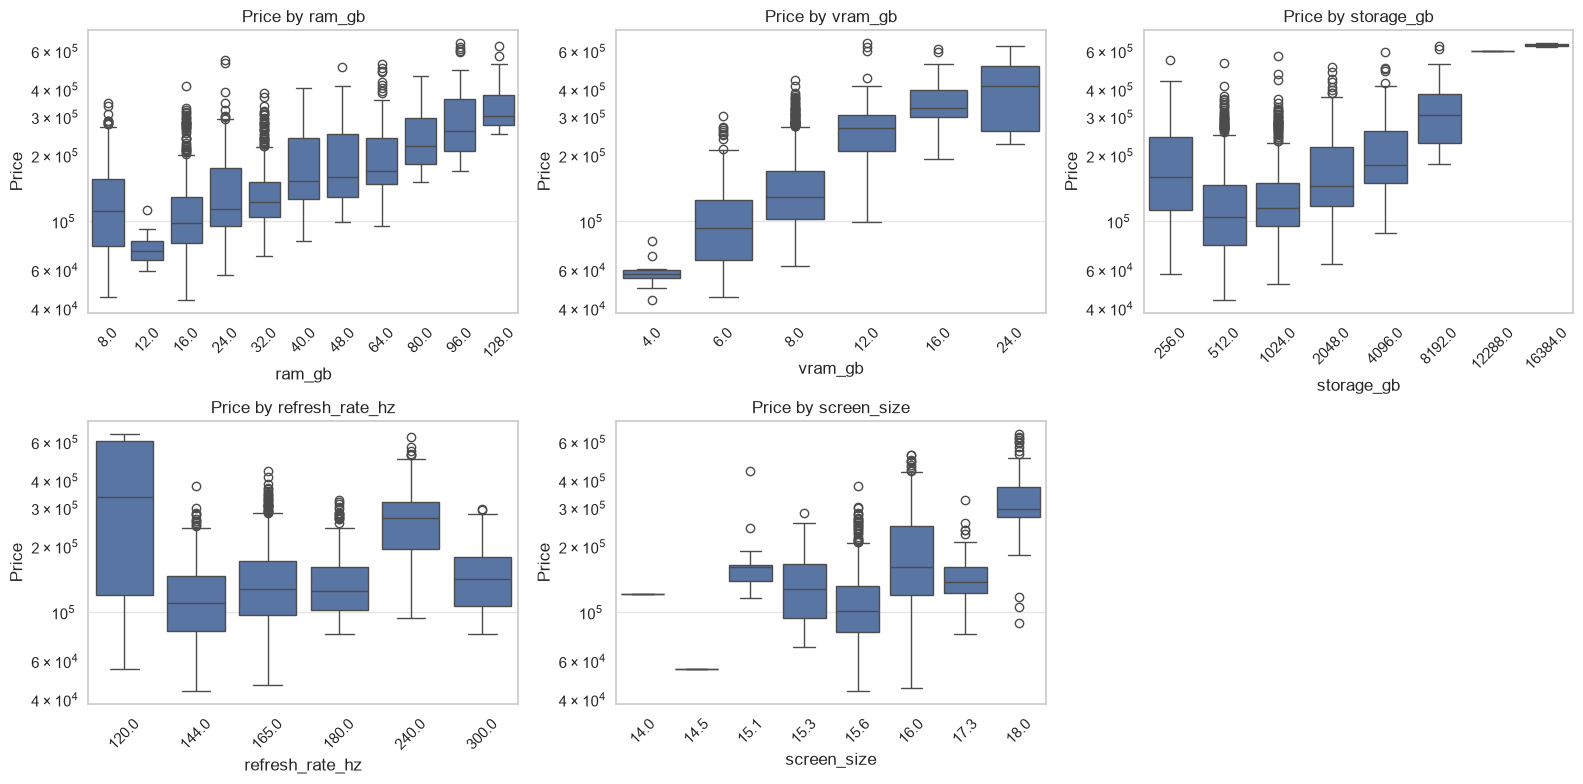

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=col, y="Price", ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"Price by {col}")
    ax.tick_params(axis="x", rotation=45)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

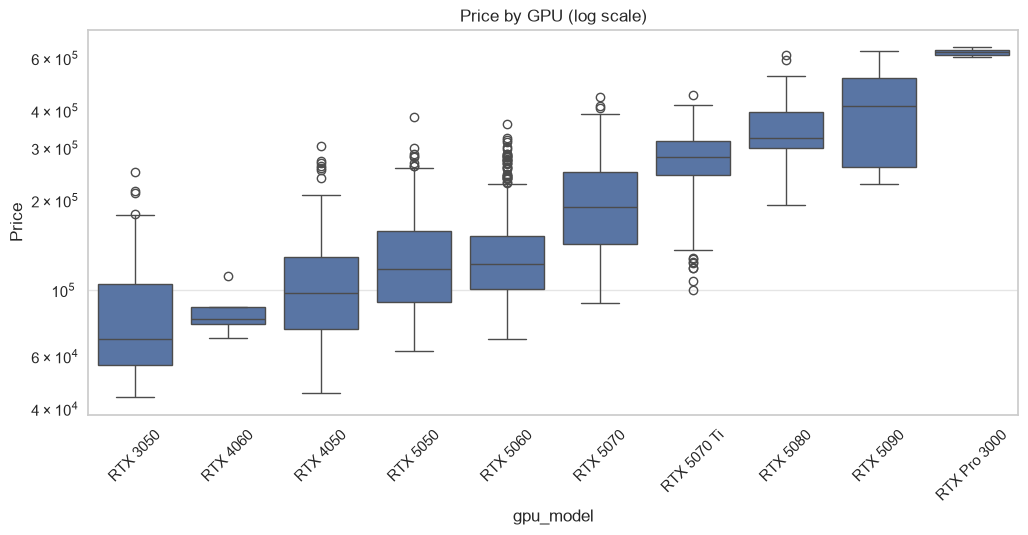

              count    median
gpu_model                    
RTX 3050        106   68397.0
RTX 4060          4   80223.0
RTX 4050        192   97974.0
RTX 5050        278  118200.0
RTX 5060        533  122606.0
RTX 5070        369  190516.0
RTX 5070 Ti      94  280394.0
RTX 5080         83  323417.0
RTX 5090         19  414744.0
RTX Pro 3000      3  628529.0


In [9]:
order = df.groupby("gpu_model")["Price"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="gpu_model", y="Price", order=order)
plt.yscale("log")
plt.xticks(rotation=45)
plt.title("Price by GPU (log scale)")
plt.show()

print(df.groupby("gpu_model")["Price"].agg(["count", "median"]).loc[order].round(0).to_string())

In [10]:
print(df["refresh_rate_hz"].value_counts().sort_index().to_string())
print(df["screen_size"].value_counts().sort_index().to_string())

refresh_rate_hz
120.0     12
144.0    543
165.0    597
180.0    133
240.0    360
300.0     36
screen_size
14.0      1
14.5      1
15.1     25
15.3     76
15.6    595
16.0    807
17.3     84
18.0     92


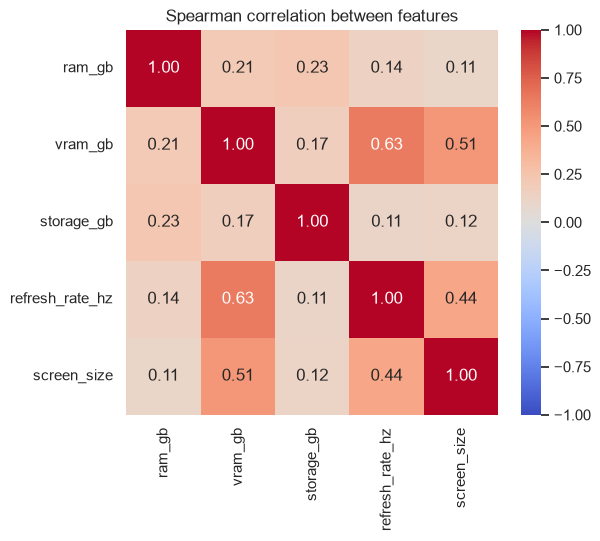

In [11]:
# 1. Are the numeric features carrying the same information?
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation between features")
plt.show()

brand
MSI            446
ASUS           313
LENOVO         312
ACER           238
CASPER         174
HP             144
GAMERAIDER      39
DELL             9
THUNDEROBOT      5
GIGABYTE         1


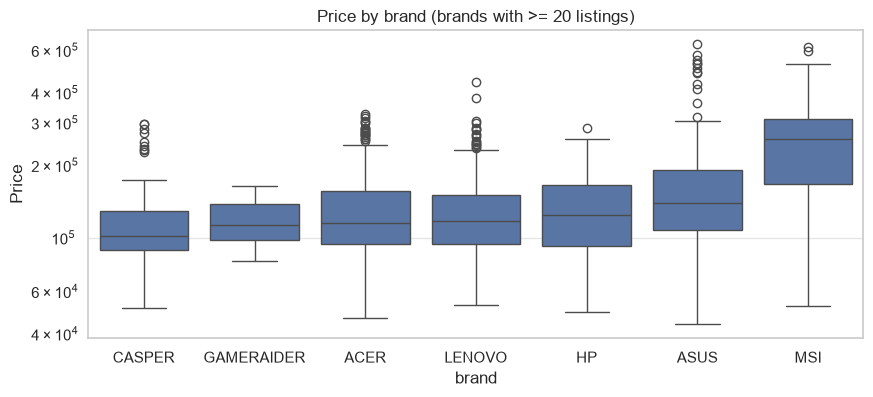

os
Windows    975
Free       706
os
Free       121095.0
Windows    147503.0


In [12]:
# 3. Brand and OS
brand_counts = df["brand"].value_counts()
print(brand_counts.to_string())

top = brand_counts[brand_counts >= 20].index
order = df[df["brand"].isin(top)].groupby("brand")["Price"].median().sort_values().index
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[df["brand"].isin(top)], x="brand", y="Price", order=order)
plt.yscale("log")
plt.title("Price by brand (brands with >= 20 listings)")
plt.show()

print(df["os"].value_counts().to_string())
print(df.groupby("os")["Price"].median().round(0).to_string())

In [13]:
def cliffs_delta(a, b):
    """P(a > b) - P(a < b). |d| < 0.15 negligible, < 0.33 small, < 0.47 medium, else large."""
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return 2 * u / (len(a) * len(b)) - 1

# 1. Within one GPU tier, do RAM / storage still correlate with price?
print("--- Spearman with Price inside one GPU tier ---")
for gpu in ["RTX 5050", "RTX 5060", "RTX 5070"]:
    sub = df[df["gpu_model"] == gpu]
    cols = [c for c in num_cols if sub[c].nunique() > 1]
    print(gpu, "| n =", len(sub), "|", {c: round(stats.spearmanr(sub[c], sub["Price"])[0], 2) for c in cols})

# 2. RTX 5070: 12 GB vs 8 GB
s = df[df["gpu_model"] == "RTX 5070"]
a, b = s.loc[s["vram_gb"] == 12, "Price"], s.loc[s["vram_gb"] == 8, "Price"]
print("\n--- RTX 5070 12GB vs 8GB ---")
print("n:", len(a), len(b), "| medians:", round(a.median()), round(b.median()),
      "| p =", round(stats.mannwhitneyu(a, b).pvalue, 4), "| delta =", round(cliffs_delta(a, b), 2))

# 3. Windows vs Free inside one GPU tier
print("\n--- Windows vs Free (same GPU) ---")
rows = []
for gpu in ["RTX 5050", "RTX 5060", "RTX 5070"]:
    s = df[df["gpu_model"] == gpu]
    w, f = s.loc[s["os"] == "Windows", "Price"], s.loc[s["os"] == "Free", "Price"]
    rows.append({"gpu": gpu, "n_win": len(w), "n_free": len(f),
                 "median_win": round(w.median()), "median_free": round(f.median()),
                 "p": round(stats.mannwhitneyu(w, f).pvalue, 4), "delta": round(cliffs_delta(w, f), 2)})
print(pd.DataFrame(rows).to_string(index=False))

# 4. Brand inside one GPU tier
print("\n--- Brand effect (same GPU) ---")
for gpu in ["RTX 5060", "RTX 5070"]:
    s = df[df["gpu_model"] == gpu]
    groups = {b: g["Price"] for b, g in s.groupby("brand") if len(g) >= 15}
    h, p = stats.kruskal(*groups.values())
    print(gpu, "| Kruskal-Wallis p =", round(p, 4), "|", {b: (len(g), round(g.median())) for b, g in groups.items()})

--- Spearman with Price inside one GPU tier ---
RTX 5050 | n = 278 | {'ram_gb': np.float64(0.7), 'storage_gb': np.float64(0.48), 'refresh_rate_hz': np.float64(-0.48), 'screen_size': np.float64(0.34)}
RTX 5060 | n = 533 | {'ram_gb': np.float64(0.64), 'storage_gb': np.float64(0.38), 'refresh_rate_hz': np.float64(0.21), 'screen_size': np.float64(0.19)}
RTX 5070 | n = 369 | {'ram_gb': np.float64(0.6), 'vram_gb': np.float64(0.42), 'storage_gb': np.float64(0.4), 'refresh_rate_hz': np.float64(0.15), 'screen_size': np.float64(-0.01)}

--- RTX 5070 12GB vs 8GB ---
n: 96 273 | medians: 240522 164079 | p = 0.0 | delta = 0.56

--- Windows vs Free (same GPU) ---
     gpu  n_win  n_free  median_win  median_free      p  delta
RTX 5050    162     116      129625       105080 0.0008   0.24
RTX 5060    293     240      130023       110385 0.0000   0.30
RTX 5070    229     140      207515       157317 0.0000   0.30

--- Brand effect (same GPU) ---
RTX 5060 | Kruskal-Wallis p = 0.0 | {'ACER': (127, 124963

## EDA Summary: Findings and Limitations

**Dataset:** 1,681 gaming laptop listings from idefix.com with a dedicated NVIDIA RTX GPU (cleaned, no missing values). Prices are in TL and were collected on a single date (*fill in the scrape date*).

### Findings

1. **Price is right-skewed, so `log(Price)` is the modeling target.** Median 135,762 TL, mean 165,255 TL. Skewness is 1.52 for the raw price and 0.29 after the log transform. The log histogram shows several peaks, consistent with distinct price segments by GPU tier. High prices (up to 652,299 TL) belong to RTX 5080/5090 and heavily upgraded models, not to errors, so they were kept.
2. **GPU tier is the strongest price driver.** Median price rises from 68,397 TL (RTX 3050) to 414,744 TL (RTX 5090). Exception: RTX 5050 (118,200 TL) and RTX 5060 (122,606 TL) cost almost the same and their distributions overlap heavily.
3. **RAM and storage carry information beyond the GPU.** Across all listings VRAM (Spearman 0.62) and RAM (0.60) correlate most with price, while RAM and storage correlate only weakly with the other features (at most 0.23). Inside a single GPU tier, RAM stays strongly related to price (0.70, 0.64, 0.60 for RTX 5050, 5060, 5070) and storage moderately (0.38 to 0.48).
4. **Refresh rate and screen size mostly reflect GPU tier.** Overall correlations are 0.48 and 0.46, but within a tier they are inconsistent (refresh rate: -0.48, 0.21, 0.15; screen size: 0.34, 0.19, -0.01). The -0.48 for RTX 5050 is unexplained. A different brand or model mix inside that tier is a plausible cause, but it was not tested.
5. **RTX 5070 listings with 12 GB VRAM cost much more than those with 8 GB.** Median 240,522 vs 164,079 TL (+47%). Mann-Whitney p < 0.001, Cliff's delta = 0.56 (large).
6. **Windows listings cost more than Free/DOS listings with the same GPU.** Median premium: +23% (RTX 5050), +18% (RTX 5060), +32% (RTX 5070). All p <= 0.001, Cliff's delta 0.24 to 0.30 (small).
7. **Brand matters within a GPU tier.** Kruskal-Wallis p < 0.001 for both RTX 5060 and RTX 5070. Median RTX 5070 price: MSI 243,244 TL, Lenovo 164,208, ASUS 156,212, HP 155,627, Casper 108,499. Median RTX 5060 price: ASUS 154,237 TL vs Casper 102,549.

### Limitations

- **Prices have not been verified against the live site.** All findings hold if the scraped prices are correct.
- **Single collection date.** Lira prices drift over time, so results describe one point in time and say nothing about trends.
- **Scope is dedicated-GPU laptops only.** Listings with no GPU in the title (office and ultrabook models) were removed during cleaning, so the findings do not apply to them, and the removed rows were not a random sample.
- **Missing VRAM was filled with the per-GPU mode.** RTX 5070 (8/12 GB) and RTX 3050 (4/6 GB) each exist in two real variants, so some filled values are probably wrong. The 8 GB group in finding 5 includes filled rows, which most likely shrinks the true gap.
- **Observational data with confounding.** The brand, OS and VRAM comparisons do not control for RAM, storage, CPU or bundled accessories. For example, many 12 GB RTX 5070 listings are MSI Raider/Crosshair models with upgraded RAM and SSD (seen in sampled titles), so the premium cannot be attributed to VRAM alone. The tests show association, not cause.
- **Observations are not fully independent.** The same product appears from several sellers (`group_id`), so p-values are optimistic. With about 1,700 rows even small differences are significant, which is why effect sizes are reported alongside p-values.
- **Very small groups.** RTX 4060 (4 listings), RTX Pro 3000 (3) and brands with fewer than 20 listings were not analyzed.
- **LLM extraction accuracy is not yet measured**, so extraction errors may still be present.
- **CPU effects were not analyzed.** This needs CPU generation and tier parsing (feature engineering).